In [1]:
import numpy as np
import uxarray as ux
from matplotlib import pyplot as plt
from scipy.interpolate import griddata, RegularGridInterpolator
import pygeode as pyg
import os, glob
from jfunctions import *
import scipy.interpolate as intp
from scipy.ndimage import uniform_filter1d
import xarray as xr
from wavenumber_frequency_functions import *


%matplotlib widget

save = False

a = 6371e3

In [2]:
data_dir = '/store/ATMOS/cwp29/mpas-a/data/ape_test/120km_update_damping/'
grid_path = data_dir + 'x1.40962.grid.nc'

#ds = pyg.open(data_dir+'latlon_diag.nc')
ds = pyg.open(data_dir+'latlon_diag.nc')
dsh = pyg.open(data_dir+'latlon_hist.nc')

In [10]:
print(ds)
print(dsh)

<Dataset>:
Vars:
  mslp                 (Time,latitude,longitude)              (406,180,360)
  height_50hPa         (Time,latitude,longitude)              (406,180,360)
  height_100hPa        (Time,latitude,longitude)              (406,180,360)
  height_200hPa        (Time,latitude,longitude)              (406,180,360)
  height_250hPa        (Time,latitude,longitude)              (406,180,360)
  height_500hPa        (Time,latitude,longitude)              (406,180,360)
  height_700hPa        (Time,latitude,longitude)              (406,180,360)
  height_850hPa        (Time,latitude,longitude)              (406,180,360)
  height_925hPa        (Time,latitude,longitude)              (406,180,360)
  w_50hPa              (Time,latitude,longitude)              (406,180,360)
  w_100hPa             (Time,latitude,longitude)              (406,180,360)
  w_200hPa             (Time,latitude,longitude)              (406,180,360)
  w_250hPa             (Time,latitude,longitude)              (406,180,

In [12]:
# TODO

zs = 0.5*(dsh.zgrid[1:, 0, 0] + dsh.zgrid[:-1, 0, 0])
dzs = dsh.zgrid[1:, 0, 0] - dsh.zgrid[:-1, 0, 0]
times = dsh.ke.Time[:]/4

# Add global kinetic energy
global_ke = np.sum((a+zs[np.newaxis, :, np.newaxis, np.newaxis])**2 * dsh.rho[:] * dsh.ke[:] * dzs[np.newaxis, :, np.newaxis, np.newaxis], axis=1)

(203,)


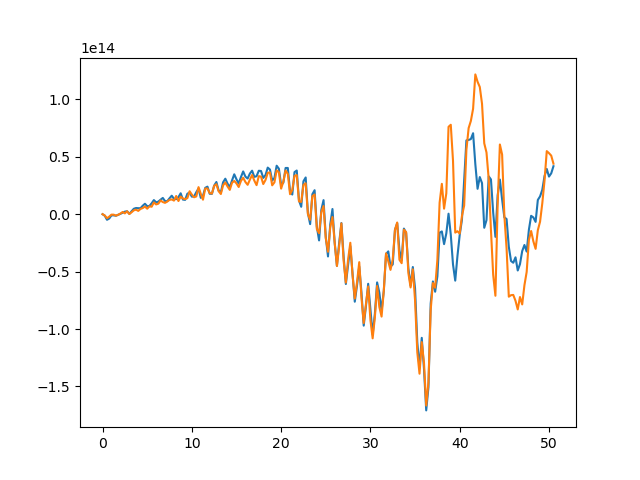

In [22]:
# Calculate damping tendency
u_damp = -dsh.rho[:, -5:] * dsh.u[:, -5:]**2 / (86400 * 6)
energy_damp = np.sum((a+zs[np.newaxis, -5:, np.newaxis, np.newaxis])**2 * u_damp * dzs[np.newaxis, -5:, np.newaxis, np.newaxis], axis=1)
global_damp = np.trapz(np.trapz(energy_damp*np.cos(sh.latitude[:][np.newaxis, :, np.newaxis]), x=sh.longitude[:], axis=2), x=sh.latitude[:], axis=1)

u_damp2 = -dsh.rho[:, -10:-5] * dsh.u[:, -10:-5]**2 / (86400 * 6)
energy_damp2 = np.sum((a+zs[np.newaxis, -10:-5, np.newaxis, np.newaxis])**2 * u_damp2 * dzs[np.newaxis, -10:-5, np.newaxis, np.newaxis], axis=1)
global_damp2 = np.trapz(np.trapz(energy_damp2*np.cos(sh.latitude[:][np.newaxis, :, np.newaxis]), x=sh.longitude[:], axis=2), x=sh.latitude[:], axis=1)
print(global_damp.shape)

plt.figure()
plt.plot(times, global_damp)
plt.plot(times, global_damp2)

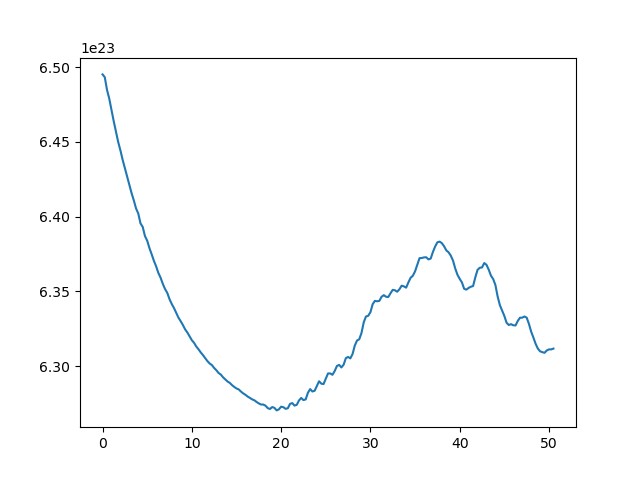

In [9]:
# Globally integrated potential temperature

global_T = np.sum((a+zs[np.newaxis, :, np.newaxis, np.newaxis])**2 * dsh.theta[:] * dzs[np.newaxis, :, np.newaxis, np.newaxis], axis=1)
global_T = np.trapz(np.trapz(global_T*np.cos(sh.latitude[:][np.newaxis, :, np.newaxis]), x=sh.longitude[:], axis=2), x=sh.latitude[:], axis=1)

plt.figure()
plt.plot(times, global_T)

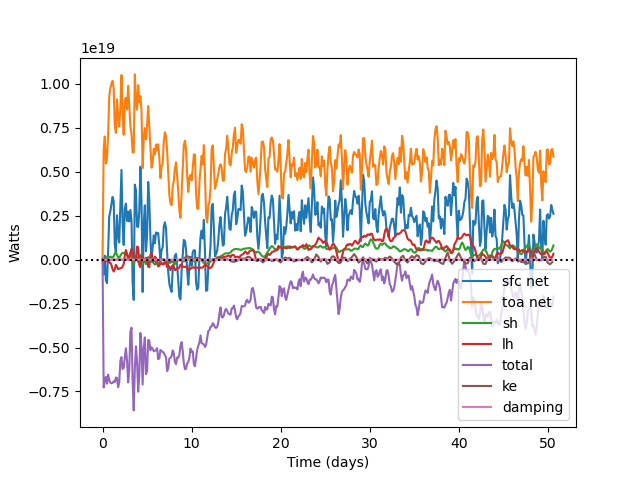

In [18]:
# global energy budget = -toa_net_radiation + sfc_net_radiation + sh + lh
# sfc_net_radiation = swupb - swdnb + lwupb - lwdnb
# toa_net_radiation = swupt - swdnt + lwupt - lwdnt

sfc_net_radiation = ds.swupb - ds.swdnb + ds.lwupb - ds.lwdnb
toa_net_radiation = ds.swupt - ds.swdnt + ds.lwupt - ds.lwdnt
sh = ds.hfx
lh = ds.lh
geb = sfc_net_radiation - toa_net_radiation + sh + lh

plt.figure()
for var, lbl in zip([sfc_net_radiation, toa_net_radiation, sh, lh, geb], ['sfc net', 'toa net', 'sh', 'lh', 'total']):
    plt.plot(var.Time[:]/8., a*a*np.trapz(np.trapz(var[:]*np.cos(var.latitude[:][np.newaxis, :, np.newaxis]), x=var.longitude[:], axis=2), x=var.latitude[:], axis=1), label=lbl)

plt.plot(times, np.gradient(np.trapz(np.trapz(global_ke[:]*np.cos(sh.latitude[:][np.newaxis, :, np.newaxis]), x=sh.longitude[:], axis=2), x=sh.latitude[:], axis=1), 24*60*60*times), label='ke')

plt.plot(times, global_damp, label='u damping')

plt.axhline(0, color='k', ls=':')
plt.ylabel("Watts")
plt.xlabel("Time (days)")
plt.legend()

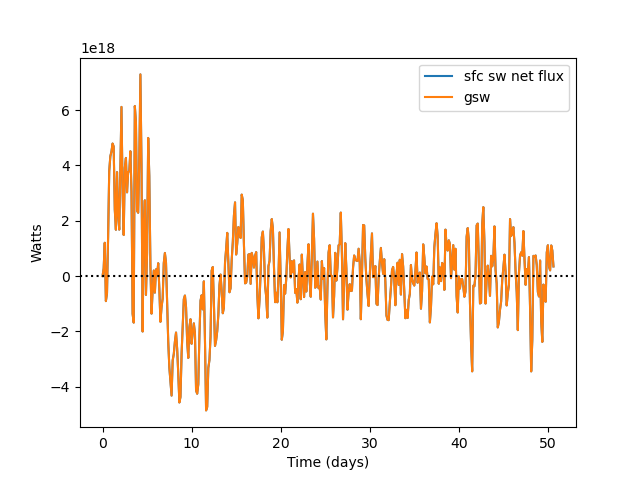

In [6]:
plot_vars = [ds.swupb - ds.swdnb, -ds.gsw]
labels = ['sfc sw net flux', 'gsw']

plt.figure()
for var, lbl in zip(plot_vars, labels):
    plt.plot(var.Time[:]/8., a*a*np.trapz(np.trapz(var[:]*np.cos(var.latitude[:][np.newaxis, :, np.newaxis]), x=var.longitude[:], axis=2), x=var.latitude[:], axis=1), label=lbl)

plt.axhline(0, color='k', ls=':')
plt.ylabel("Watts")
plt.xlabel("Time (days)")
plt.legend()

In [7]:
lwupflx = 5.67e-8*ds.temperature_surface**4

plot_vars = [ds.lwupb, 5.67e-8*ds.sst**4, ds.lwdnt + ds.lwdnb, ds.glw]
labels = ['lw up flux', r"$\sigma T^4$", 'lw dn flux', 'glw']

plt.figure()
for var, lbl in zip(plot_vars, labels):
    plt.plot(var.Time[:]/8., a*a*np.trapz(np.trapz(var[:]*np.cos(var.latitude[:][np.newaxis, :, np.newaxis]), x=var.longitude[:], axis=2), x=var.latitude[:], axis=1), label=lbl)

plt.axhline(0, color='k', ls=':')
plt.ylabel("Watts")
plt.xlabel("Time (days)")
plt.legend()

AttributeError: sst